# Análisis de Sensibilidad y Estabilidad de LSH-HLA con Frobenius Kernel
Este notebook realiza un estudio detallado del comportamiento del algoritmo Hashing Sensible a la Localidad (LSH-HLA) utilizando exclusivamente el **kernel de proyección de Frobenius**:
1. **Análisis de Estabilidad (10 corridas):** Evalúa la variabilidad del rendimiento y tiempos de ejecución del algoritmo bajo parámetros fijos (`num_proj=5`, `B=40`) realizando 10 corridas independientes.
2. **Análisis de Sensibilidad de Buckets (B = 10, 40, 100, 300):** Analiza el efecto del parámetro $B$ (número de divisiones de bucket) sobre la calidad de clasificación y el tiempo de ejecución.

Toda la divergencia JS y entropía espectral se calcula usando la mezcla de matrices de densidad 50/50 normalizada para evitar sesgos de tamaño de cluster.


In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
from sklearn.metrics import precision_recall_fscore_support

# ----------------------------------------------------
# 1. Kernel de Frobenius y Base del Algoritmo
# ----------------------------------------------------

def projection_frobenius(A, B):
    # Producto interno de Frobenius literal (traza de A.T @ B)
    return np.trace(np.dot(A.T, B))


def hash_p_stable(projection, r):
    if r <= 0:
        return 0
    b = np.random.uniform(0, r)
    return int(np.floor((projection + b) / r))


def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g


def get_adjacency(g, N):
    if 'adjacency' in g.graph:
        return g.graph['adjacency']

    g_copy = g.copy()
    g_copy.remove_edges_from(nx.selfloop_edges(g_copy))

    nodes_order = list(sorted(g_copy.nodes()))

    A = nx.adjacency_matrix(
        g_copy,
        nodelist=nodes_order,
        weight='weight'
    ).toarray().astype(float)

    M = A.shape[0]
    A = np.pad(A, [(0, N - M), (0, N - M)], mode="constant")

    if not g.graph.get('is_merged', False):
        A = (A > 0).astype(float)

    np.fill_diagonal(A, 0)
    g.graph['adjacency'] = A
    return A


def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)


def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))


def von_newmann_entropy(g):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    A = get_adjacency(g, 10)
    rho = get_density_matrix(A)
    entropy = entropy_from_rho(rho)
    
    g.graph['vn_entropy'] = entropy
    g.graph['rho'] = rho
    return entropy


def get_rho(g, N):
    if 'rho' in g.graph:
        return g.graph['rho']
    A = get_adjacency(g, N)
    rho = get_density_matrix(A)
    g.graph['rho'] = rho
    return rho


def aggregate(g1, g2, N):
    A1 = get_adjacency(g1, N)
    A2 = get_adjacency(g2, N)

    A = A1 + A2
    np.fill_diagonal(A, 0)
    
    g = nx.from_numpy_array(A)
    g.graph['is_merged'] = True
    return g


def js_divergence(g1, g2, N):
    rho1 = get_rho(g1, N)
    rho2 = get_rho(g2, N)

    rho_mix = (rho1 + rho2) / 2.0

    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)


def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_adjacency(g, N_pad)

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r)
        bucket_id += f"{hash_bin}_"

    return bucket_id


def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if len(active) == 0:
        return 0.0

    if N_pad is None:
        N_pad = max(g.number_of_nodes() for g in clusters.values())

    active_graphs = [clusters[i] for i in active]

    if h_total is None:
        active_rhos = [get_rho(g, N_pad) for g in active_graphs]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

    if h_total <= 1e-12:
        return 0.0

    H_C = np.mean([
        von_newmann_entropy(g)
        for g in active_graphs
    ])

    q = 1.0 - (H_C / h_total)
    return float(q)


def refill_heap_global(active, clusters, N_pad):
    heap = []
    active_list = list(active)

    for a in range(len(active_list)):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]

            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    return heap


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

# ----------------------------------------------------
# 2. Controladores LSH-HLA
# ----------------------------------------------------

def build_lsh_buckets(graphs, num_proj, B, proj_func, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in range(num_proj):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)
        A_er = get_adjacency(erg, N_pad)

        projections = []
        for g in graphs:
            A = get_adjacency(g, N_pad)
            proj = proj_func(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)
        projection_ranges.append((min_proj, max_proj))

        r = (max_proj - min_proj) / B
        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)
    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges


def hierarchical_bucket_heap_dynamic(
    graphs,
    buckets,
    bucket_ids,
    random_graphs,
    projection_ranges,
    B,
    proj_func,
    epsilon=np.inf
):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}
    cluster_bucket = {i: bucket_ids[i] for i in range(num_graphs)}

    bucket_members = defaultdict(set)
    for bid, indices in buckets.items():
        bucket_members[bid].update(indices)

    # h_total basado en promedio de matrices de densidad de todos los grafos activos
    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)
    
    heap = []
    for bid, members in bucket_members.items():
        members = list(members)
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                i = members[a]
                j = members[b]
                dist = js_divergence(clusters[i], clusters[j], N_pad)
                heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs
    global_mode = False

    while len(active) > 1:
        if not global_mode and not has_bucket_candidates(bucket_members, active):
            global_mode = True
            heap = refill_heap_global(active, clusters, N_pad)

        if len(heap) == 0:
            if global_mode:
                heap = refill_heap_global(active, clusters, N_pad)
            else:
                break

        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if not global_mode and cluster_bucket[i] != cluster_bucket[j]:
            continue

        if dist > epsilon:
            break

        same_bucket = cluster_bucket[i] == cluster_bucket[j]
        old_bucket_i = cluster_bucket[i]
        old_bucket_j = cluster_bucket[j]

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)

        active.remove(i)
        active.remove(j)
        bucket_members[old_bucket_i].discard(i)
        bucket_members[old_bucket_j].discard(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        new_bucket_id = get_bucket_id_for_graph(
            new_graph,
            random_graphs=random_graphs,
            B=B,
            projection_ranges=projection_ranges,
            N_pad=N_pad,
            proj_func=proj_func
        )
        cluster_bucket[new_id] = new_bucket_id
        bucket_members[new_bucket_id].add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id, new_bucket_id, same_bucket, global_mode])

        if global_mode:
            for other in list(active):
                if other == new_id:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))
        else:
            for other in list(bucket_members[new_bucket_id]):
                if other == new_id or other not in active:
                    continue
                new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
                heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active, bucket_members


def shclust_heap_dynamic(graphs, num_proj=3, B=10, proj_func=projection_frobenius, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B,
        proj_func=proj_func
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        proj_func=proj_func,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

# ----------------------------------------------------
# 3. Helpers de Evaluación
# ----------------------------------------------------

def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships[c_i] + memberships[c_j]
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}


def evaluate_clustering(Z, num_graphs, true_labels):
    target_merges = num_graphs - 2
    cluster_members = get_cluster_memberships(Z, num_graphs, target_merges)
    
    clusters_list = list(cluster_members.values())
    
    best_f1 = -1.0
    best_preds = None
    
    # Evaluar las dos asignaciones posibles a clases binarias
    for mapping in [(0, 1), (1, 0)]:
        temp_preds = np.zeros(num_graphs, dtype=int)
        for idx in clusters_list[0]:
            temp_preds[idx] = mapping[0]
        for idx in clusters_list[1]:
            temp_preds[idx] = mapping[1]
            
        _, _, f1, _ = precision_recall_fscore_support(true_labels, temp_preds, average='binary', zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_preds = temp_preds
            
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, best_preds, average='binary', zero_division=0)
    accuracy = np.mean(best_preds == true_labels)
    return precision, recall, f1, accuracy


def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    active = set(range(num_graphs))
    clusters = {i: graphs[i] for i in range(num_graphs)}

    active_rhos = [get_rho(clusters[i], N_pad) for i in active]
    rho_total = np.mean(active_rhos, axis=0)
    h_total = entropy_from_rho(rho_total)

    heap = []
    active_list = list(active)
    for a in tqdm(range(len(active_list)), desc="Inicializando heap"):
        for b in range(a + 1, len(active_list)):
            i = active_list[a]
            j = active_list[b]
            dist = js_divergence(clusters[i], clusters[j], N_pad)
            heappush(heap, (dist, i, j))

    Z = []
    next_cluster_id = num_graphs

    while len(active) > 1 and len(heap) > 0:
        dist, i, j = heappop(heap)
        if i not in active or j not in active:
            continue

        if dist > epsilon:
            break

        new_id = next_cluster_id
        next_cluster_id += 1

        new_graph = aggregate(clusters[i], clusters[j], N_pad)
        active.remove(i)
        active.remove(j)

        clusters[new_id] = new_graph
        active.add(new_id)

        # Recalcular h_total
        active_rhos = [get_rho(clusters[x], N_pad) for x in active]
        rho_total = np.mean(active_rhos, axis=0)
        h_total = entropy_from_rho(rho_total)

        q = quality(active=active, clusters=clusters, h_total=h_total, N_pad=N_pad)
        Z.append([i, j, dist, q, new_id])

        for other in list(active):
            if other == new_id:
                continue
            new_dist = js_divergence(clusters[new_id], clusters[other], N_pad)
            heappush(heap, (new_dist, new_id, other))

    return Z, clusters, active


In [2]:
# Configurar semillas para reproducibilidad del dataset
np.random.seed(42)
random.seed(42)

graphs = []
true_labels = []

# Generar 500 grafos estrella aleatorios con ruido
for _ in range(500):
    g = nx.star_graph(9)
    edges = list(g.edges())
    g.remove_edge(*random.choice(edges))
    while True:
        u, v = random.sample(range(10), 2)
        if not g.has_edge(u, v):
            g.add_edge(u, v)
            break
    graphs.append(g)
    true_labels.append(0)

# Generar 500 grafos ciclo aleatorios con ruido
for _ in range(500):
    g = nx.cycle_graph(10)
    edges = list(g.edges())
    g.remove_edge(*random.choice(edges))
    while True:
        u, v = random.sample(range(10), 2)
        if not g.has_edge(u, v):
            g.add_edge(u, v)
            break
    graphs.append(g)
    true_labels.append(1)

# Mezclar el dataset
indices = list(range(1000))
random.shuffle(indices)

graphs = [graphs[i] for i in indices]
true_labels = np.array([true_labels[i] for i in indices])

print(f"Dataset generado:")
print(f"Total de grafos: {len(graphs)}")
print(f"Grafos Estrella (clase 0): {np.sum(true_labels == 0)}")
print(f"Grafos Ciclo (clase 1): {np.sum(true_labels == 1)}")


Dataset generado:
Total de grafos: 1000
Grafos Estrella (clase 0): 500
Grafos Ciclo (clase 1): 500


## 1. Estabilidad de LSH-HLA y Baseline con Frobenius Kernel (10 Corridas)
Evaluamos y comparamos el comportamiento de LSH-HLA ($B=40, num\_proj=5$) y del Baseline (sin LSH) a lo largo de 10 ejecuciones independientes.
Reportamos para ambos:
1. **Buckets Únicos:** Cantidad de recipientes LSH distintos generados.
2. **Paso de Fusión ($k^*$):** El paso de codo de la curva de calidad.
3. **Cant. Clusters Óptima:** Número de agrupamientos resultantes.
4. **Tiempo ($s$):** Duración total de la corrida en segundos.


In [3]:
NUM_RUNS = 10
NUM_PROJ_FIXED = 5
B_FIXED = 40
num_graphs_syn = len(graphs)

from collections import Counter

def calculate_mode(values):
    rounded_vals = [round(v, 2) if isinstance(v, float) else v for v in values]
    counts = Counter(rounded_vals)
    mode_val, _ = counts.most_common(1)[0]
    return mode_val

def largest_marginal_drop_method(q):
    """Selecciona la partición anterior a la mayor pérdida de q(C).

    Para una caída entre los merges k y k + 1, se conserva k,
    evitando la fusión que degrada más la calidad de partición.
    """
    q = np.asarray(q, dtype=float)
    if q.size < 2:
        raise ValueError("Se requieren al menos dos pasos de fusión.")

    drops = q[:-1] - q[1:]
    k_star = int(np.argmax(drops) + 1)
    return k_star, drops

# ----------------------------------------------------
# 1.1. Estabilidad de LSH-HLA
# ----------------------------------------------------
print(f"Ejecutando {NUM_RUNS} corridas de LSH-HLA...")
run_data_lsh = []
np.random.seed(42)
random.seed(42)

for r in tqdm(range(NUM_RUNS), desc="Corridas LSH"):
    start_time = time.time()
    Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
        graphs,
        num_proj=NUM_PROJ_FIXED,
        B=B_FIXED,
        proj_func=projection_frobenius,
        epsilon=np.inf
    )
    elapsed = time.time() - start_time
    
    df_B = pd.DataFrame(
        Z_B,
        columns=[
            "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
            "new_bucket_id", "same_bucket", "global_mode"
        ]
    )
    k_star, _ = largest_marginal_drop_method(df_B["q"].values)
    num_clusters = df_B.shape[0] - k_star + 1
    unique_buckets = len(set(bucket_ids))
    
    run_data_lsh.append({
        "Corrida": r + 1,
        "Buckets Únicos": unique_buckets,
        "Paso de Fusión (k*)": k_star,
        "Cant. Clusters Óptima": num_clusters,
        "Tiempo (seg)": elapsed
    })

df_stability_lsh = pd.DataFrame(run_data_lsh)
print("\n=== ESTABILIDAD DE LSH-HLA (10 Corridas) ===")
print(df_stability_lsh.to_string(index=False))

print("\n=== ESTADÍSTICAS GLOBALES LSH-HLA (Media ± Desv. Estándar) ===")
stats_lsh = pd.DataFrame({
    "Métrica": ["Buckets Únicos", "Paso de Fusión (k*)", "Cant. Clusters Óptima", "Tiempo (seg)"],
    "Promedio": [
        df_stability_lsh["Buckets Únicos"].mean(),
        df_stability_lsh["Paso de Fusión (k*)"].mean(),
        df_stability_lsh["Cant. Clusters Óptima"].mean(),
        df_stability_lsh["Tiempo (seg)"].mean()
    ],
    "Desv. Estándar": [
        df_stability_lsh["Buckets Únicos"].std(),
        df_stability_lsh["Paso de Fusión (k*)"].std(),
        df_stability_lsh["Cant. Clusters Óptima"].std(),
        df_stability_lsh["Tiempo (seg)"].std()
    ],
    "Moda": [
        calculate_mode(df_stability_lsh["Buckets Únicos"].values),
        calculate_mode(df_stability_lsh["Paso de Fusión (k*)"].values),
        calculate_mode(df_stability_lsh["Cant. Clusters Óptima"].values),
        calculate_mode(df_stability_lsh["Tiempo (seg)"].values)
    ]
})
print(stats_lsh.to_string(index=False))

# ----------------------------------------------------
# 1.2. Estabilidad del Baseline (10 Corridas)
# ----------------------------------------------------
print(f"\nEjecutando {NUM_RUNS} corridas del Baseline (sin LSH)...")
run_data_base = []

for r in tqdm(range(NUM_RUNS), desc="Corridas Baseline"):
    start_time = time.time()
    Z_base, _, _ = hierarchical_clustering_heap(graphs, epsilon=np.inf)
    elapsed = time.time() - start_time
    
    df_base = pd.DataFrame(
        Z_base,
        columns=["cluster_i", "cluster_j", "dist", "q", "new_cluster_id"]
    )
    k_star, _ = largest_marginal_drop_method(df_base["q"].values)
    num_clusters = df_base.shape[0] - k_star + 1
    
    run_data_base.append({
        "Corrida": r + 1,
        "Buckets Únicos": "N/A",
        "Paso de Fusión (k*)": k_star,
        "Cant. Clusters Óptima": num_clusters,
        "Tiempo (seg)": elapsed
    })

df_stability_base = pd.DataFrame(run_data_base)
print("\n=== ESTABILIDAD DEL BASELINE (10 Corridas) ===")
print(df_stability_base.to_string(index=False))

print("\n=== ESTADÍSTICAS GLOBALES BASELINE (Media ± Desv. Estándar) ===")
stats_base = pd.DataFrame({
    "Métrica": ["Buckets Únicos", "Paso de Fusión (k*)", "Cant. Clusters Óptima", "Tiempo (seg)"],
    "Promedio": [
        "N/A",
        df_stability_base["Paso de Fusión (k*)"].mean(),
        df_stability_base["Cant. Clusters Óptima"].mean(),
        df_stability_base["Tiempo (seg)"].mean()
    ],
    "Desv. Estándar": [
        "N/A",
        df_stability_base["Paso de Fusión (k*)"].std(),
        df_stability_base["Cant. Clusters Óptima"].std(),
        df_stability_base["Tiempo (seg)"].std()
    ],
    "Moda": [
        "N/A",
        calculate_mode(df_stability_base["Paso de Fusión (k*)"].values),
        calculate_mode(df_stability_base["Cant. Clusters Óptima"].values),
        calculate_mode(df_stability_base["Tiempo (seg)"].values)
    ]
})
print(stats_base.to_string(index=False))


Ejecutando 10 corridas de LSH-HLA...


Corridas LSH: 100%|██████████| 10/10 [00:45<00:00,  4.58s/it]



=== ESTABILIDAD DE LSH-HLA (10 Corridas) ===
 Corrida  Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima  Tiempo (seg)
       1             218                  998                      2      4.456470
       2             270                  998                      2      4.993913
       3             170                  998                      2      3.395489
       4             222                  998                      2      4.593148
       5             217                  998                      2      4.771519
       6             205                  998                      2      4.065644
       7             249                  998                      2      4.907719
       8             272                  998                      2      5.511559
       9             188                  998                      2      3.560775
      10             289                  998                      2      5.485527

=== ESTADÍSTICAS GLOBALES LSH-HLA (Media

Corridas Baseline: 100%|██████████| 10/10 [05:24<00:00, 32.46s/it]


=== ESTABILIDAD DEL BASELINE (10 Corridas) ===
 Corrida Buckets Únicos  Paso de Fusión (k*)  Cant. Clusters Óptima  Tiempo (seg)
       1            N/A                  998                      2     32.302248
       2            N/A                  998                      2     33.653549
       3            N/A                  998                      2     33.450446
       4            N/A                  998                      2     32.573376
       5            N/A                  998                      2     32.833950
       6            N/A                  998                      2     32.888603
       7            N/A                  998                      2     31.676002
       8            N/A                  998                      2     31.971208
       9            N/A                  998                      2     31.379369
      10            N/A                  998                      2     31.849214

=== ESTADÍSTICAS GLOBALES BASELINE (Media ± Desv.

## 2. Sensibilidad al número de divisiones del bucket ($B$)
Fijando el kernel de **Frobenius** y el número de proyecciones a `num_proj=5`, evaluamos la sensibilidad del algoritmo LSH-HLA para diferentes valores de $B \in [10, 40, 100, 300]$, realizando 10 ejecuciones por valor.


Evaluando análisis de sensibilidad sobre B (10 ejecuciones por valor)...
Evaluando B = 10...
Evaluando B = 40...
Evaluando B = 100...
Evaluando B = 300...

=== REPORTE DE SENSIBILIDAD DE B (10 ejecuciones por valor) ===
  B  Buckets_Mean  Buckets_Std  Buckets_Mode  KStar_Mean  KStar_Std  KStar_Mode  Clusters_Mean  Clusters_Std  Clusters_Mode  Time_Mean  Time_Std  Time_Mode
 10         294.4    61.676900           348       998.0        0.0         998            2.0           0.0              2   5.350668  0.952652       5.89
 40         195.2    77.248689           174       998.0        0.0         998            2.0           0.0              2   4.121787  1.522974       3.59
100         258.9    81.169514           281       998.0        0.0         998            2.0           0.0              2   5.105211  1.476445       5.29
300         104.6    14.874139            98       998.0        0.0         998            2.0           0.0              2   2.868721  0.175328       2.77


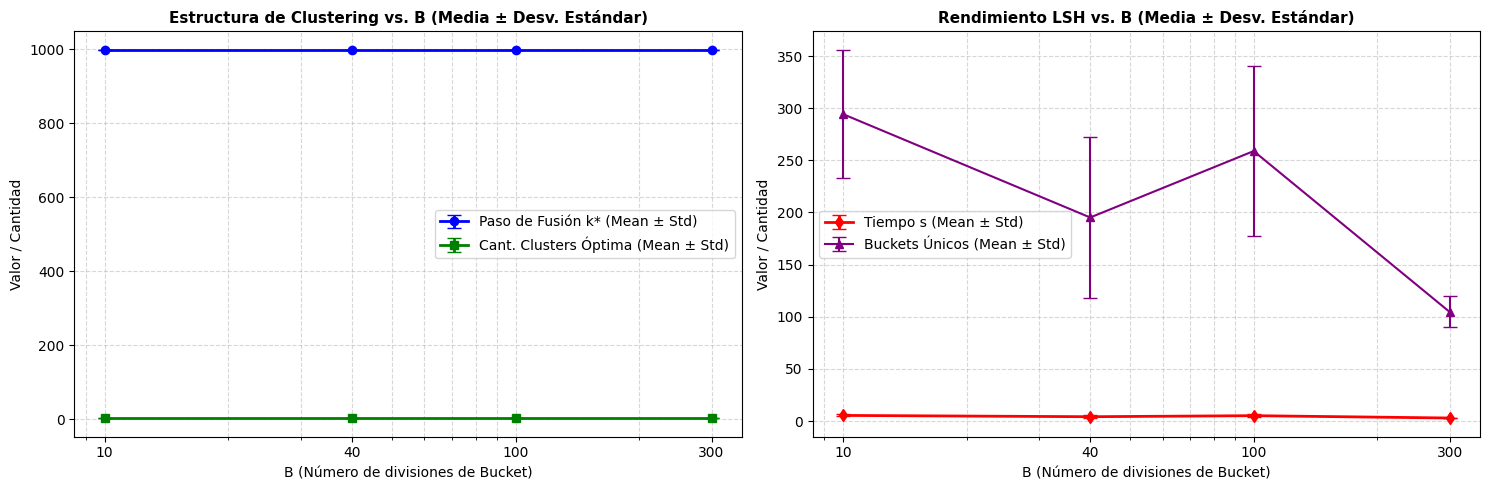

In [4]:
B_values = [10, 40, 100, 300]
NUM_PROJ_SENSITIVITY = 5
REPS_PER_B = 10

sensitivity_results = []

print("Evaluando análisis de sensibilidad sobre B (10 ejecuciones por valor)...")
np.random.seed(42)
random.seed(42)

for B_val in B_values:
    print(f"Evaluando B = {B_val}...")
    temp_buckets = []
    temp_kstar = []
    temp_clusters = []
    temp_time = []
    
    for _ in range(REPS_PER_B):
        start_time = time.time()
        Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
            graphs,
            num_proj=NUM_PROJ_SENSITIVITY,
            B=B_val,
            proj_func=projection_frobenius,
            epsilon=np.inf
        )
        elapsed = time.time() - start_time
        
        df_B = pd.DataFrame(
            Z_B,
            columns=[
                "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
                "new_bucket_id", "same_bucket", "global_mode"
            ]
        )
        k_star, _ = largest_marginal_drop_method(df_B["q"].values)
        num_clusters = df_B.shape[0] - k_star + 1
        unique_buckets = len(set(bucket_ids))
        
        temp_buckets.append(unique_buckets)
        temp_kstar.append(k_star)
        temp_clusters.append(num_clusters)
        temp_time.append(elapsed)
        
    sensitivity_results.append({
        "B": B_val,
        
        "Buckets_Mean": np.mean(temp_buckets),
        "Buckets_Std": np.std(temp_buckets),
        "Buckets_Mode": calculate_mode(temp_buckets),
        
        "KStar_Mean": np.mean(temp_kstar),
        "KStar_Std": np.std(temp_kstar),
        "KStar_Mode": calculate_mode(temp_kstar),
        
        "Clusters_Mean": np.mean(temp_clusters),
        "Clusters_Std": np.std(temp_clusters),
        "Clusters_Mode": calculate_mode(temp_clusters),
        
        "Time_Mean": np.mean(temp_time),
        "Time_Std": np.std(temp_time),
        "Time_Mode": calculate_mode(temp_time)
    })

# Convertir a DataFrame y presentar reporte
df_sensitivity = pd.DataFrame(sensitivity_results)
print("\n=== REPORTE DE SENSIBILIDAD DE B (10 ejecuciones por valor) ===")
print(df_sensitivity.to_string(index=False))

# ----------------------------------------------------
# Visualización de Sensibilidad con Barras de Error
# ----------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Paso de Fusión y Número de Clusters
ax1.errorbar(df_sensitivity["B"], df_sensitivity["KStar_Mean"], yerr=df_sensitivity["KStar_Std"], 
             marker='o', label="Paso de Fusión k* (Mean ± Std)", color="blue", linewidth=2, capsize=5)
ax1.errorbar(df_sensitivity["B"], df_sensitivity["Clusters_Mean"], yerr=df_sensitivity["Clusters_Std"], 
             marker='s', label="Cant. Clusters Óptima (Mean ± Std)", color="green", linewidth=2, capsize=5)

ax1.set_xscale('log')
ax1.set_xticks(B_values)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_title("Estructura de Clustering vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax1.set_xlabel("B (Número de divisiones de Bucket)")
ax1.set_ylabel("Valor / Cantidad")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()

# Subplot 2: Tiempo de corrida y Buckets Únicos
ax2.errorbar(df_sensitivity["B"], df_sensitivity["Time_Mean"], yerr=df_sensitivity["Time_Std"], 
             marker='d', color="red", linewidth=2, capsize=5, label="Tiempo s (Mean ± Std)")
ax2.errorbar(df_sensitivity["B"], df_sensitivity["Buckets_Mean"], yerr=df_sensitivity["Buckets_Std"], 
             marker='^', color="purple", linewidth=1.5, capsize=5, label="Buckets Únicos (Mean ± Std)")
ax2.set_xscale('log')
ax2.set_xticks(B_values)
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.set_title("Rendimiento LSH vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax2.set_xlabel("B (Número de divisiones de Bucket)")
ax2.set_ylabel("Valor / Cantidad")
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Comparativa de Corrida Individual: LSH-HLA vs Baseline (Sin LSH)
En esta sección realizamos una comparación directa de una corrida individual entre:
1. **LSH-HLA (Con LSH):** Usando el kernel de Frobenius con `num_proj=5` y `B=40`.
2. **Baseline (Sin LSH):** El algoritmo jerárquico tradicional completo sobre todos los pares de grafos.

Se reporta y grafica la F1-score de clasificación (%) y el tiempo de ejecución (segundos) para mostrar la ganancia en velocidad manteniendo la precisión de agrupamiento.


=== Ejecutando Baseline (Sin LSH) ===


Inicializando heap: 100%|██████████| 1000/1000 [00:15<00:00, 63.55it/s]


Baseline completado en 33.42s | F1-Score: 100.00%

=== Ejecutando LSH-HLA (Con LSH, Frobenius) ===
LSH-HLA completado en 4.35s | F1-Score: 100.00%

=== TABLA COMPARATIVA ===
            Método  F1-Score (%)  Tiempo (segundos)
 LSH-HLA (Con LSH)         100.0           4.350296
Baseline (Sin LSH)         100.0          33.415051


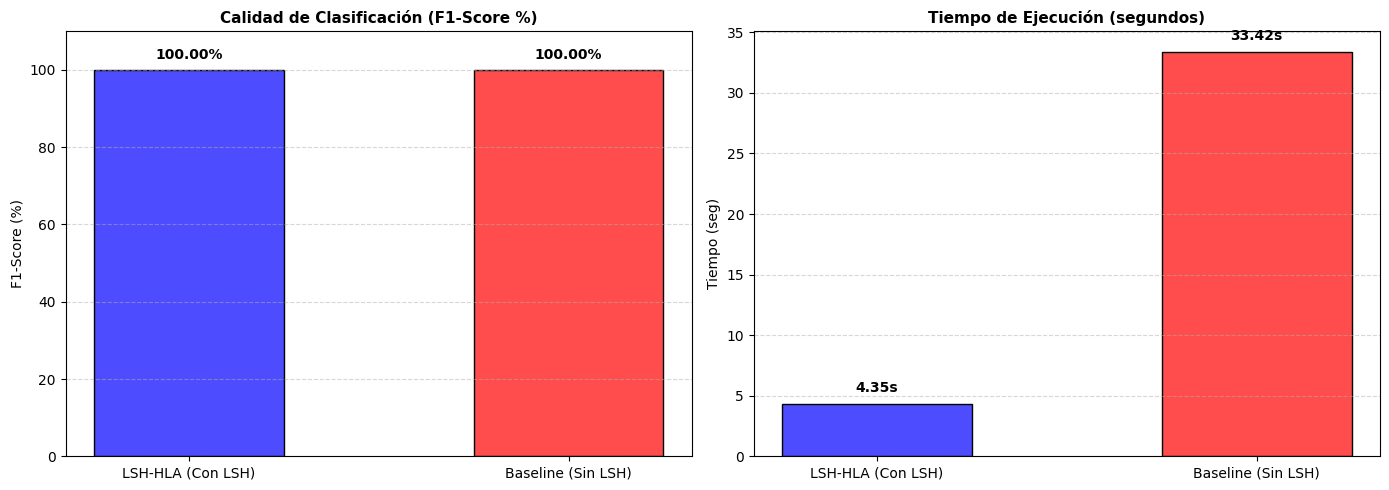

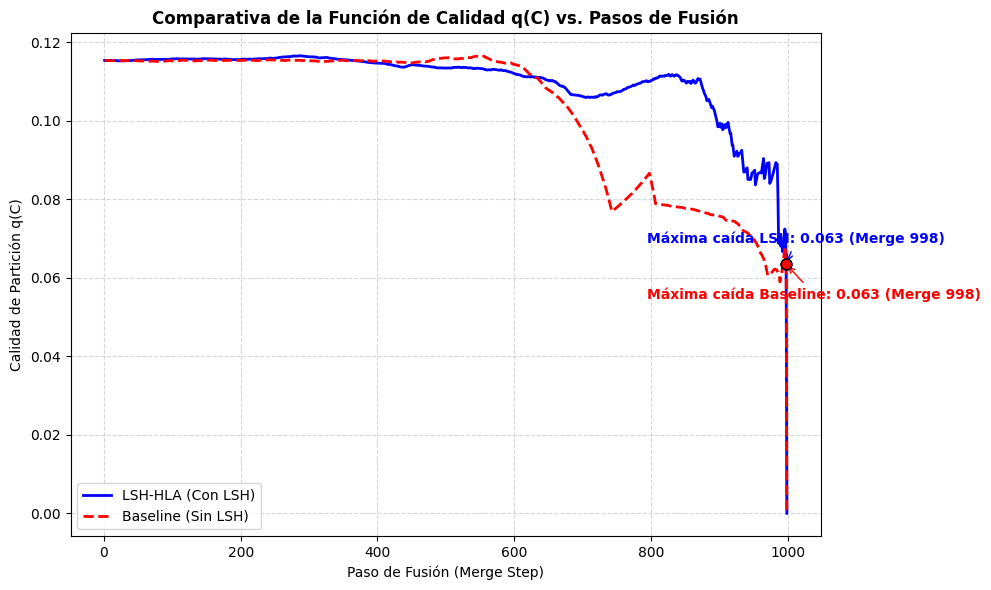

In [5]:
# 1. Ejecutar Baseline (Sin LSH)
print("=== Ejecutando Baseline (Sin LSH) ===")
start_time = time.time()
# hierarchical_clustering_heap retorna Z, clusters, active
Z_baseline, _, _ = hierarchical_clustering_heap(graphs)
time_baseline = time.time() - start_time
_, _, f1_baseline, _ = evaluate_clustering(Z_baseline, len(graphs), true_labels)
print(f"Baseline completado en {time_baseline:.2f}s | F1-Score: {f1_baseline*100:.2f}%\n")

# 2. Ejecutar LSH-HLA (Con LSH)
print("=== Ejecutando LSH-HLA (Con LSH, Frobenius) ===")
start_time = time.time()
np.random.seed(42)
random.seed(42)
# shclust_heap_dynamic retorna Z, clusters, active, bucket_members, bucket_ids
Z_lsh, _, _, _, _ = shclust_heap_dynamic(
    graphs,
    num_proj=5,
    B=40,
    proj_func=projection_frobenius
)
time_lsh = time.time() - start_time
_, _, f1_lsh, _ = evaluate_clustering(Z_lsh, len(graphs), true_labels)
print(f"LSH-HLA completado en {time_lsh:.2f}s | F1-Score: {f1_lsh*100:.2f}%\n")

# 3. Crear DataFrame comparativo
df_comparison = pd.DataFrame({
    "Método": ["LSH-HLA (Con LSH)", "Baseline (Sin LSH)"],
    "F1-Score (%)": [f1_lsh * 100, f1_baseline * 100],
    "Tiempo (segundos)": [time_lsh, time_baseline]
})

print("=== TABLA COMPARATIVA ===")
print(df_comparison.to_string(index=False))

# 4. Graficar comparativa de Barras (F1 y Tiempo)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#4D4DFF", "#FF4D4D"]

# Graficar F1-Score
bars1 = ax1.bar(df_comparison["Método"], df_comparison["F1-Score (%)"], color=colors, edgecolor="black", width=0.5)
ax1.set_title("Calidad de Clasificación (F1-Score %)", fontsize=11, fontweight="bold")
ax1.set_ylabel("F1-Score (%)")
ax1.set_ylim(0, 110)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")

# Graficar Tiempo de corrida
bars2 = ax2.bar(df_comparison["Método"], df_comparison["Tiempo (segundos)"], color=colors, edgecolor="black", width=0.5)
ax2.set_title("Tiempo de Ejecución (segundos)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Tiempo (seg)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + (time_baseline * 0.02), f"{yval:.2f}s", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

# 5. Graficar Curvas de la Función de Calidad q(C)
df_lsh = pd.DataFrame(
    Z_lsh,
    columns=[
        "cluster_i",
        "cluster_j",
        "dist",
        "q",
        "new_cluster_id",
        "new_bucket_id",
        "same_bucket",
        "global_mode"
    ]
)
df_lsh["merge"] = range(1, len(df_lsh) + 1)
k_star_lsh, _ = largest_marginal_drop_method(df_lsh["q"].values)
x_drop_lsh = k_star_lsh
y_drop_lsh = df_lsh.loc[k_star_lsh - 1, "q"]

df_base = pd.DataFrame(
    Z_baseline,
    columns=[
        "cluster_i",
        "cluster_j",
        "dist",
        "q",
        "new_cluster_id"
    ]
)
df_base["merge"] = range(1, len(df_base) + 1)
k_star_base, _ = largest_marginal_drop_method(df_base["q"].values)
x_drop_base = k_star_base
y_drop_base = df_base.loc[k_star_base - 1, "q"]

plt.figure(figsize=(10, 6))

# Trazar curvas
plt.plot(df_lsh["merge"], df_lsh["q"], color="blue", label="LSH-HLA (Con LSH)", linewidth=2)
plt.plot(df_base["merge"], df_base["q"], color="red", linestyle="--", label="Baseline (Sin LSH)", linewidth=2)

# Resaltar la partición anterior a la máxima caída
plt.scatter(x_drop_lsh, y_drop_lsh, color="blue", zorder=5, s=60, edgecolors="black")
plt.scatter(x_drop_base, y_drop_base, color="red", zorder=5, s=60, edgecolors="black")

# Anotaciones
plt.annotate(
    f"Máxima caída LSH: {y_drop_lsh:.3f} (Merge {x_drop_lsh})",
    (x_drop_lsh, y_drop_lsh),
    textcoords="offset points",
    xytext=(-100, 15),
    fontweight="bold",
    color="blue",
    arrowprops=dict(arrowstyle="->", color="blue")
)

plt.annotate(
    f"Máxima caída Baseline: {y_drop_base:.3f} (Merge {x_drop_base})",
    (x_drop_base, y_drop_base),
    textcoords="offset points",
    xytext=(-100, -25),
    fontweight="bold",
    color="red",
    arrowprops=dict(arrowstyle="->", color="red")
)

plt.xlabel("Paso de Fusión (Merge Step)")
plt.ylabel("Calidad de Partición q(C)")
plt.title("Comparativa de la Función de Calidad q(C) vs. Pasos de Fusión", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()


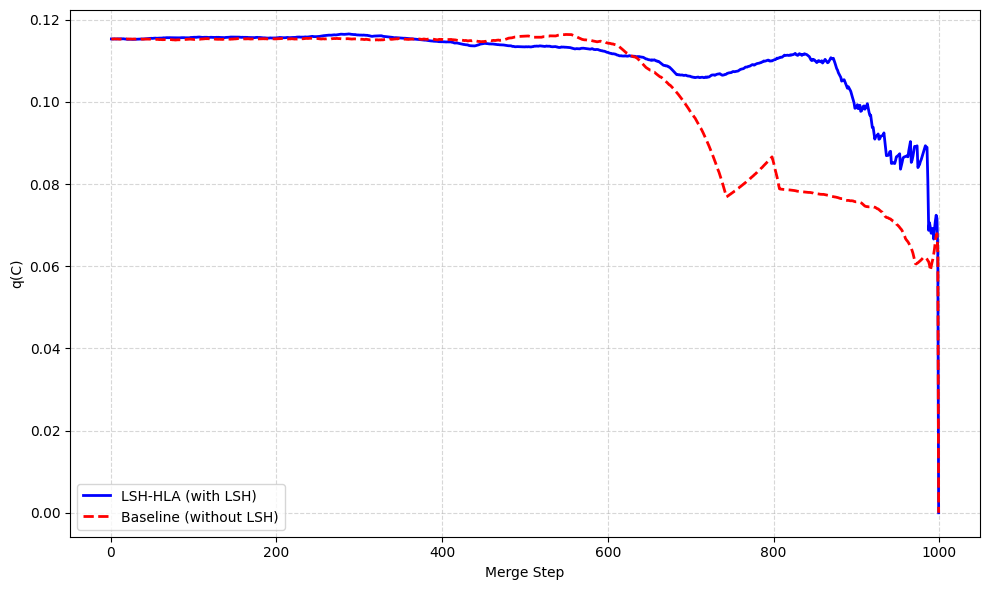

In [9]:

plt.figure(figsize=(10, 6))

plt.plot(df_lsh["merge"], df_lsh["q"], color="blue", label="LSH-HLA (with LSH)", linewidth=2)
plt.plot(df_base["merge"], df_base["q"], color="red", linestyle="--", label="Baseline (without LSH)", linewidth=2)

plt.xlabel("Merge Step")
plt.ylabel("q(C)")
#plt.title("Quality Function q(C) vs. Merge Steps", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()